In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Ячейка используется, чтобы при запуске ноутбука из папки notebooks,
# можно было импортировать модули из других папок проекта.

In [2]:
import config

print('SEED:', config.SEED) # проверка, что ноутбук видит другие папки

SEED: 42


In [3]:
from catboost.datasets import msrank_10k
import pandas as pd

train_df, test_df = msrank_10k()
train_df.rename(columns={0: "target", 1: "query_id"}, inplace=True)
test_df.rename(columns={0: "target", 1: "query_id"}, inplace=True)
print(train_df.shape, test_df.shape)
print(train_df.head())

(10000, 138) (10000, 138)
   target  query_id  2  3  4  5  6    7    8         9  ...  128       129  \
0     2.0         1  3  3  0  0  3  1.0  1.0  0.000000  ...   62  11089534   
1     2.0         1  3  0  3  0  3  1.0  0.0  1.000000  ...   54  11089534   
2     0.0         1  3  0  2  0  3  1.0  0.0  0.666667  ...   45         3   
3     2.0         1  3  0  3  0  3  1.0  0.0  1.000000  ...   56  11089534   
4     1.0         1  3  0  3  0  3  1.0  0.0  1.000000  ...   64         5   

   130  131    132  133  134  135  136  137  
0    2  116  64034   13    3    0    0  0.0  
1    2  124  64034    1    2    0    0  0.0  
2    1  124   3344   14   67    0    0  0.0  
3   13  123  63933    1    3    0    0  0.0  
4    7  256  49697    1   13    0    0  0.0  

[5 rows x 138 columns]


/tmp/ipykernel_11654/3709616058.py:5: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train_df.rename(columns={0: "target", 1: "query_id"}, inplace=True)
/tmp/ipykernel_11654/3709616058.py:6: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test_df.rename(columns={0: "target", 1: "query_id"}, inplace=True)


In [4]:
full_df = pd.concat([train_df, test_df], ignore_index=True)
print(full_df.shape)
print("Unique queries:", full_df['query_id'].nunique())

(20000, 138)
Unique queries: 175


In [5]:
query_sizes = full_df.groupby("query_id").size()
print(query_sizes.describe())
print("5-й перцентиль:", query_sizes.quantile(0.05))
print("95-й перцентиль:", query_sizes.quantile(0.95))
print("Максимум:", query_sizes.max())

count    175.000000
mean     114.285714
std       58.447329
min        2.000000
25%       77.000000
50%      103.000000
75%      139.000000
max      370.000000
dtype: float64
5-й перцентиль: 42.7
95-й перцентиль: 227.59999999999997
Максимум: 370


In [6]:
print(full_df["target"].value_counts(normalize=True).sort_index())

target
0.0    0.56180
1.0    0.29150
2.0    0.12735
3.0    0.01450
4.0    0.00485
Name: proportion, dtype: float64


In [7]:
# ищем запросы, у которых нет релевантных документов (target < 1)
queries_with_relevant = full_df[full_df["target"] > 0]["query_id"].unique()
all_queries = full_df["query_id"].unique()
empty_queries = set(all_queries) - set(queries_with_relevant)
print(f"Запросов без релевантных документов: {len(empty_queries)} из {len(all_queries)}")

Запросов без релевантных документов: 3 из 175


In [8]:
# Исключаем пустые запросы из датасета
full_df = full_df[full_df["query_id"].isin(queries_with_relevant)].copy()
print("После фильтрации:", full_df.shape, "| Запросов:", full_df["query_id"].nunique())

После фильтрации: (19939, 138) | Запросов: 172


In [9]:
import config

config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
full_df.to_pickle(config.DATA_PROCESSED / "full_df.pkl")
print("Сохранено:", config.DATA_PROCESSED / "full_df.pkl")

Сохранено: /home/piterburzhec/Work-Edu/ranking-project/data/processed/full_df.pkl


In [10]:
import numpy as np

def split_by_query(df, frac_a=0.6, frac_b=0.2, seed=42):
    qids = df["query_id"].unique()
    rng = np.random.RandomState(seed)
    rng.shuffle(qids)
    n = len(qids)
    a = set(qids[:int(n * frac_a)])
    b = set(qids[int(n * frac_a):int(n * (frac_a + frac_b))])
    c = set(qids[int(n * (frac_a + frac_b)):])
    return a, b, c

a_qids, b_qids, c_qids = split_by_query(full_df)
print(f"Часть A: {len(a_qids)} запросов")
print(f"Часть B: {len(b_qids)} запросов")
print(f"Часть C: {len(c_qids)} запросов")

Часть A: 103 запросов
Часть B: 34 запросов
Часть C: 35 запросов


In [11]:
assert len(a_qids & b_qids) == 0, "Утечка A∩B"
assert len(a_qids & c_qids) == 0, "Утечка A∩C"
assert len(b_qids & c_qids) == 0, "Утечка B∩C"
print("Пересечений нет — разбиение корректно")

Пересечений нет — разбиение корректно


In [12]:
import config

df_a = full_df[full_df["query_id"].isin(a_qids)].copy()
df_b = full_df[full_df["query_id"].isin(b_qids)].copy()
df_c = full_df[full_df["query_id"].isin(c_qids)].copy()

# Сохраняем, чтобы не пересчитывать
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

df_a.to_pickle(config.DATA_PROCESSED / "df_a.pkl")
df_b.to_pickle(config.DATA_PROCESSED / "df_b.pkl")
df_c.to_pickle(config.DATA_PROCESSED / "df_c.pkl")

In [13]:
def prepare_lgb_data(df, feature_cols, label_col="target"):
    df_sorted = df.sort_values("query_id").reset_index(drop=True)
    X = df_sorted[feature_cols].values
    y = df_sorted[label_col].values
    group = df_sorted.groupby("query_id").size().values
    return X, y, group, df_sorted

In [14]:
import lightgbm as lgb

# Для дешёвой модели берём подмножество признаков
cheap_features = [i for i in range(2, 32)]  # Признаки с 2 по 31 (всего 30 признаков)

X_a_cheap, y_a, group_a, df_a_sorted = prepare_lgb_data(df_a, cheap_features)

cheap_ranker = lgb.LGBMRanker(
    objective="lambdarank",
    metric="ndcg",
    ndcg_eval_at=[10],
    n_estimators=80,
    learning_rate=0.1,
    num_leaves=15,
    max_depth=5,
    random_state=42,
    verbose=-1,
)

cheap_ranker.fit(
    X_a_cheap, y_a,
    group=group_a,
)

/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")


,num_leaves,15
,max_depth,5
,n_estimators,80
,objective,'lambdarank'
,random_state,42
,metric,'ndcg'
,ndcg_eval_at,[10]
,verbose,-1
,boosting_type,'gbdt'
,learning_rate,0.1
,subsample_for_bin,200000


In [15]:
from catboost import CatBoostRanker, Pool
import pandas as pd

all_features = [c for c in df_a.columns if c not in ("target", "query_id")]

# Подготовка данных в формате CatBoost (group_id = per-sample)
def prepare_catboost_data(df, feature_cols, label_col="target"):
    df_sorted = df.sort_values("query_id").reset_index(drop=True)
    X = df_sorted[feature_cols].values.astype("float32")
    y = df_sorted[label_col].values.astype("float32")
    group_id = df_sorted["query_id"].values  # per-sample, длина = n_samples
    return X, y, group_id, df_sorted

X_a_full, y_a_full, group_id_a, df_a_sorted = prepare_catboost_data(df_a, all_features)

train_pool = Pool(
    data=X_a_full,
    label=y_a_full,
    group_id=group_id_a,
)
expensive_ranker = CatBoostRanker(
    loss_function="YetiRank",
    iterations=300,
    learning_rate=0.05,
    depth=7,
    random_seed=42,
    verbose=50,  # печатать прогресс каждые 50 итераций
)

expensive_ranker.fit(train_pool)

0:	total: 112ms	remaining: 33.5s
50:	total: 2.9s	remaining: 14.2s
100:	total: 5.75s	remaining: 11.3s
150:	total: 8.39s	remaining: 8.28s
200:	total: 11s	remaining: 5.4s
250:	total: 13.5s	remaining: 2.64s
299:	total: 16.1s	remaining: 0us


CatBoostRanker(depth=7, iterations=300, learning_rate=0.05, loss_function='YetiRank', random_seed=42, verbose=50)

In [16]:
def ndcg_at_k(y_true, y_score, k=10):
    """NDCG@k. Документы со score=-inf (вне top-K каскада) не дают вклада в DCG."""
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    order = np.argsort(y_score)[::-1][:k]
    y_true_sorted = y_true[order].copy()

    # Документы вне top-K приходят как -inf -> их вклад в DCG обнуляем
    unscored = ~np.isfinite(y_score[order])
    y_true_sorted[unscored] = 0

    discounts = 1.0 / np.log2(np.arange(2, len(y_true_sorted) + 2))
    dcg = np.sum((2.0 ** y_true_sorted - 1.0) * discounts)

    ideal_order = np.argsort(y_true)[::-1][:k]
    ideal_sorted = y_true[ideal_order]
    idcg = np.sum((2.0 ** ideal_sorted - 1.0) * discounts[:len(ideal_sorted)])

    return float(dcg / idcg) if idcg > 0 else 0.0

In [17]:
def cascade_predict(cheap_model, expensive_model, df, k,
                    cheap_features, all_features):
    """Прогон каскада. Возвращает DataFrame по ВСЕМ документам запроса:
    top-K дешёвой модели получают скоры дорогой, остальные — -inf.
    """
    results = []
    for qid, group in df.groupby("query_id"):
        group = group.reset_index(drop=True)

        X_cheap = group[cheap_features].values
        cheap_scores = cheap_model.predict(X_cheap)

        top_k_idx = np.argsort(cheap_scores)[::-1][:k]
        X_expensive = group.iloc[top_k_idx][all_features].values
        expensive_scores = expensive_model.predict(X_expensive)

        # Выравниваем по всем строкам запроса: вне top-K -> -inf
        aligned_scores = np.full(len(group), -np.inf, dtype=np.float64)
        aligned_scores[top_k_idx] = expensive_scores

        results.append(pd.DataFrame({
            "query_id": qid,
            "target": group["target"].values,
            "score": aligned_scores,
        }))

    return pd.concat(results, ignore_index=True)

In [18]:
import config

fixed_k_results = []

for k in config.K_GRID:
    preds = cascade_predict(
        cheap_ranker, expensive_ranker, df_c, k,
        cheap_features, all_features,
    )

    # NDCG@10 по каждому запросу. target и score уже в preds — длины совпадают
    ndcgs = [
        ndcg_at_k(group["target"].values, group["score"].values, k=10)
        for _, group in preds.groupby("query_id")
    ]
    mean_ndcg = float(np.mean(ndcgs))

    # Средняя стоимость на запрос: n_docs * cheap + min(k, n_docs) * expensive
    per_query_cost = [
        len(g) * config.COST_CHEAP + min(k, len(g)) * config.COST_EXPENSIVE
        for _, g in df_c.groupby("query_id")
    ]
    mean_cost = float(np.mean(per_query_cost))

    fixed_k_results.append({
        "K": k,
        "mean_ndcg@10": mean_ndcg,
        "mean_cost": mean_cost,
    })
    print(f"K={k:4d} | NDCG@10={mean_ndcg:.4f} | cost={mean_cost:7.1f}")

fixed_df = pd.DataFrame(fixed_k_results)
config.REPORTS.mkdir(parents=True, exist_ok=True)
fixed_df.to_csv(config.REPORTS / "fixed_k_results.csv", index=False)
print("\nСохранено:", config.REPORTS / "fixed_k_results.csv")
print(fixed_df.to_string(index=False))

/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it in

K=   5 | NDCG@10=0.2583 | cost=  160.1


/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it in

K=  10 | NDCG@10=0.3736 | cost=  208.6


/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it in

K=  20 | NDCG@10=0.4050 | cost=  305.2


... (9 outputs left out)

K= 150 | NDCG@10=0.4718 | cost= 1143.2


/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it in

K= 200 | NDCG@10=0.4720 | cost= 1188.3
K= 230 | NDCG@10=0.4720 | cost= 1205.5

Сохранено: /home/piterburzhec/Work-Edu/ranking-project/reports/fixed_k_results.csv
  K  mean_ndcg@10   mean_cost
  5      0.258344  160.057143
 10      0.373615  208.628571
 20      0.404993  305.200000
 30      0.445191  399.485714
 50      0.465391  584.628571
 75      0.467737  795.485714
100      0.470990  968.914286
150      0.471832 1143.200000
200      0.472024 1188.342857
230      0.472024 1205.485714


/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it instead of 'eval_at' argument
  _log_warning(f"Found '{alias}' in params. Will use it instead of 'eval_at' argument")
/home/piterburzhec/Work-Edu/ranking-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:969: UserWarning: Found 'ndcg_eval_at' in params. Will use it in

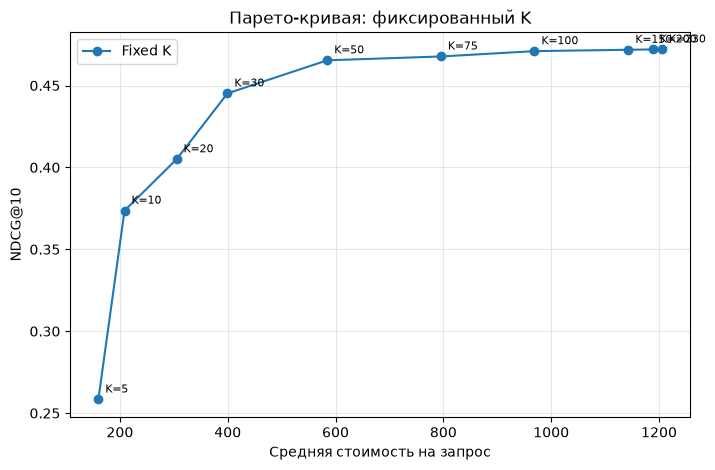

Сохранено: /home/piterburzhec/Work-Edu/ranking-project/figures/pareto_fixed_k.png


In [19]:
import config
import matplotlib.pyplot as plt

config.FIGURES.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 5))
plt.plot(fixed_df["mean_cost"], fixed_df["mean_ndcg@10"], "o-", label="Fixed K")
for _, row in fixed_df.iterrows():
    plt.annotate(
        f"K={int(row['K'])}",
        (row["mean_cost"], row["mean_ndcg@10"]),
        textcoords="offset points", xytext=(5, 5), fontsize=8,
    )
plt.xlabel("Средняя стоимость на запрос")
plt.ylabel("NDCG@10")
plt.title("Парето-кривая: фиксированный K")
plt.legend()
plt.grid(True, alpha=0.3)

out_path = config.FIGURES / "pareto_fixed_k.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print("Сохранено:", out_path)

In [20]:
import config
import pandas as pd
import cascade
import evaluation as ev

# --- 1. Sanity-check моделей ---
print("=" * 60)
print("1. Проверка моделей")
print("=" * 60)

n_trees_cb = expensive_ranker.tree_count_
n_trees_lgb = cheap_ranker.booster_.num_trees()
print(f"CatBoost деревьев: {n_trees_cb}   (ожидание: ~300)")
print(f"LightGBM деревьев: {n_trees_lgb}   (ожидание: ~80)")

assert n_trees_cb >= 200, f"CatBoost: {n_trees_cb} деревьев — модель недотренирована"
assert n_trees_lgb >= 50, f"LightGBM: {n_trees_lgb} деревьев — модель недотренирована"

# --- 2. Sanity-check метаданных ---
print("\n" + "=" * 60)
print("2. Проверка метаданных")
print("=" * 60)

print(f"cheap_features: {len(cheap_features)} шт., первые 5: {cheap_features[:5]}")
print(f"all_features: {len(all_features)} шт., первые 5: {all_features[:5]}")
assert len(cheap_features) == 30, f"cheap: {len(cheap_features)} != 30"
assert len(all_features) == 136, f"all: {len(all_features)} != 136"

# --- 3. Sanity-check fixed_df ---
print("\n" + "=" * 60)
print("3. Проверка fixed_k_results")
print("=" * 60)

print(fixed_df.to_string(index=False))

# NDCG должен быть максимальным при K=all, минимальным при K=min
assert fixed_df.iloc[-1]["mean_ndcg@10"] > fixed_df.iloc[0]["mean_ndcg@10"], \
    "NDCG не растёт с K — что-то не так с каскадом"
print("OK: NDCG растёт с K, как и ожидалось")

# --- 4. Сохранение всех артефактов ---
print("\n" + "=" * 60)
print("4. Сохранение артефактов")
print("=" * 60)

config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
config.REPORTS.mkdir(parents=True, exist_ok=True)
config.FIGURES.mkdir(parents=True, exist_ok=True)

# Модели
cascade.save_models(cheap_ranker, expensive_ranker)

# Метаданные признаков
features_meta = {
    "cheap_features": list(cheap_features),
    "all_features": list(all_features),
    "label_col": "target",
    "query_col": "query_id",
    "seed": config.SEED,
    "n_queries_a": df_a["query_id"].nunique(),
    "n_queries_b": df_b["query_id"].nunique(),
    "n_queries_c": df_c["query_id"].nunique(),
    "k_grid": list(config.K_GRID),
    "cost_cheap": config.COST_CHEAP,
    "cost_expensive": config.COST_EXPENSIVE,
}
pd.to_pickle(features_meta, config.DATA_PROCESSED / "features_meta.pkl")
print(f"features_meta.pkl сохранён: {features_meta['n_queries_a']}A/"
      f"{features_meta['n_queries_b']}B/{features_meta['n_queries_c']}C, "
      f"cheap={len(cheap_features)}, all={len(all_features)}")

# Fixed-K таблица
fixed_df.to_csv(config.REPORTS / "fixed_k_results.csv", index=False)
print(f"fixed_k_results.csv сохранён: {len(fixed_df)} строк")

# Сплиты (если ещё не сохранены в Дне 1 — сохранены, но проверим)
for name in ["df_a", "df_b", "df_c"]:
    p = config.DATA_PROCESSED / f"{name}.pkl"
    assert p.exists(), f"{name}.pkl не найден — пересохраните"
print("df_a.pkl, df_b.pkl, df_c.pkl уже на месте")

# --- 5. Финальный листинг ---
print("\n" + "=" * 60)
print("5. Артефакты на диске")
print("=" * 60)

for p in sorted(config.DATA_PROCESSED.glob("*")):
    if p.is_file():
        size_mb = p.stat().st_size / 1024 / 1024
        print(f"  {p.name:30s}  {size_mb:6.2f} МБ")

print("\n" + "=" * 60)
print("День 1 закрыт. Артефакты готовы для Дня 2.")
print("=" * 60)

1. Проверка моделей
CatBoost деревьев: 300   (ожидание: ~300)
LightGBM деревьев: 80   (ожидание: ~80)

2. Проверка метаданных
cheap_features: 30 шт., первые 5: [2, 3, 4, 5, 6]
all_features: 136 шт., первые 5: [2, 3, 4, 5, 6]

3. Проверка fixed_k_results
  K  mean_ndcg@10   mean_cost
  5      0.258344  160.057143
 10      0.373615  208.628571
 20      0.404993  305.200000
 30      0.445191  399.485714
 50      0.465391  584.628571
 75      0.467737  795.485714
100      0.470990  968.914286
150      0.471832 1143.200000
200      0.472024 1188.342857
230      0.472024 1205.485714
OK: NDCG растёт с K, как и ожидалось

4. Сохранение артефактов
Модели сохранены в /home/piterburzhec/Work-Edu/ranking-project/data/processed
features_meta.pkl сохранён: 103A/34B/35C, cheap=30, all=136
fixed_k_results.csv сохранён: 10 строк
df_a.pkl, df_b.pkl, df_c.pkl уже на месте

5. Артефакты на диске
  cheap_ranker.txt                  0.13 МБ
  df_a.pkl                         12.49 МБ
  df_b.pkl             